# Лабораторная работа 2
## Дообучение диалоговых моделей `decoder-only` и `encoder-decoder`

### Задание

1. Выбрать подходящую модель https://huggingface.co/models.
2. Выбрать подходящий датасет https://huggingface.co/datasets.
3. Проверить работу модели в сценарии, близком к выбранному датасету, в zero-shot режиме.
4. Посчитать метрики `BLEU` и `METEOR` исходной модели на валидационном сабсете.
5. Дообучить модель на обучающем сабсете.
6. Проверить работу модели после обучения.
7. Посчитать метрики `BLEU` и `METEOR` обученной модели.
8. Сравнить метрики обученной и исходной моделей.

### Выбранные данные

- Датасет: [`HuggingFaceH4/ultrachat_200k`](https://huggingface.co/datasets/HuggingFaceH4/ultrachat_200k)
- Decoder-only модель: [`HuggingFaceTB/SmolLM2-135M-Instruct`](https://huggingface.co/HuggingFaceTB/SmolLM2-135M-Instruct)
- Encoder-decoder модель: [`google/flan-t5-small`](https://huggingface.co/google/flan-t5-small)

### Почему я выбрал именно эти модели и датасет

Для `decoder-only` я взял `SmolLM2-135M-Instruct`. Это небольшая модель, которая уже умеет работать с сообщениями пользователя и ассистента. Мне показалось, что с неё будет удобно начать, потому что у неё есть готовый шаблон диалога, а сама модель не такая большая, как многие другие языковые модели на Hugging Face. Так проще попробовать полноценное дообучение

Для `encoder-decoder` выбрал `FLAN-T5-small`. Она тоже относительно небольшая, но устроена по-другому: сначала обрабатывает входной текст, а затем генерирует ответ. Она уже обучалась выполнять текстовые инструкции, поэтому подходит для задания

Датасет `UltraChat 200k` подходит для диалоговой задачи, потому что в нём уже есть сообщения пользователя и ответы ассистента. Для простоты беру только первые два сообщения каждого подходящего диалога: запрос пользователя и первый ответ ассистента. Дальше обе модели будут учиться на одинаковых парах

Для обучения использую 1000 примеров из `train_sft`, а для проверки 100 примеров из `test_sft`. Это небольшие выборки относительно всего датасета. Здесь `test_sft` используется как валидационная выборка, поэтому отдельную финальную проверку на независимом тесте не провожу

#### Импорт

In [1]:
import gc
import random
from pathlib import Path

import datasets
import evaluate
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoModelForSeq2SeqLM, AutoTokenizer

print("PyTorch:", torch.__version__)
print("Transformers:", __import__("transformers").__version__)
print("Datasets:", datasets.__version__)

PyTorch: 2.7.1+cu126
Transformers: 5.19.0
Datasets: 4.8.5


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Устройство:", device)
if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))

Устройство: cuda
Видеокарта: NVIDIA GeForce GTX 1060 6GB


### Data preprocessing

Зададим основные параметры в одном месте.

`FAST_MODE = True` был нужен, чтобы проверить код на маленькой выборке

In [3]:
DATASET_NAME = "HuggingFaceH4/ultrachat_200k"
SMOL_MODEL_NAME = "HuggingFaceTB/SmolLM2-135M-Instruct"
FLAN_MODEL_NAME = "google/flan-t5-small"

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
HF_CACHE_DIR = Path("hf_cache")

DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
HF_CACHE_DIR.mkdir(exist_ok=True)

MAX_INPUT_LENGTH = 192
MAX_TARGET_LENGTH = 128

BATCH_SIZE = 1
GRADIENT_ACCUMULATION = 8
NUM_EPOCHS = 10
LEARNING_RATE = 5e-5

EARLY_STOPPING = True
PATIENCE = 3
MIN_DELTA = 0.0

FAST_MODE = False
FAST_TRAIN_SIZE = 100
FAST_VAL_SIZE = 20
TRAIN_SIZE = 1000
VAL_SIZE = 100

if FAST_MODE:
    TRAIN_SIZE = FAST_TRAIN_SIZE
    VAL_SIZE = FAST_VAL_SIZE

MODE_NAME = "fast" if FAST_MODE else "full"

PAIRS_DIR = DATA_DIR / f"ultrachat_smol_v1_{TRAIN_SIZE}_{VAL_SIZE}_{MAX_INPUT_LENGTH}_{MAX_TARGET_LENGTH}"
SMOL_FINETUNED_DIR = MODEL_DIR / f"smollm2_135m_best_val_{MODE_NAME}"
FLAN_FINETUNED_DIR = MODEL_DIR / f"flan_t5_small_best_val_{MODE_NAME}"

print("Режим:", MODE_NAME)
print("Train:", TRAIN_SIZE, "	Validation:", VAL_SIZE)
print("Максимум эпох:", NUM_EPOCHS, "	Early stopping:", EARLY_STOPPING)


Режим: full
Train: 1000 	Validation: 100
Максимум эпох: 10 	Early stopping: True


#### Загрузка токенизаторов

Для SmolLM2 и FLAN-T5 используются разные токенизаторы. У SmolLM2 есть готовый шаблон диалога

In [4]:
smol_tokenizer = AutoTokenizer.from_pretrained(
    SMOL_MODEL_NAME,
    cache_dir=HF_CACHE_DIR,
)

flan_tokenizer = AutoTokenizer.from_pretrained(
    FLAN_MODEL_NAME,
    cache_dir=HF_CACHE_DIR,
)

print("SmolLM2 pad token:", smol_tokenizer.pad_token)
print("SmolLM2 eos token:", smol_tokenizer.eos_token)
print("FLAN-T5 pad token:", flan_tokenizer.pad_token)

SmolLM2 pad token: <|im_end|>
SmolLM2 eos token: <|im_end|>
FLAN-T5 pad token: <pad>


In [5]:
def make_smol_prompt(question):
    messages = [
        {"role": "user", "content": question}
    ]

    prompt = smol_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    prompt_ids = smol_tokenizer.encode(
        prompt,
        add_special_tokens=False
    )

    return prompt_ids

def make_flan_prompt(question):
    return f"Respond to the user message:\n{question}"


print(smol_tokenizer.decode(make_smol_prompt("Hello!")))
print(make_flan_prompt("Hello!"))

<|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
Hello!<|im_end|>
<|im_start|>assistant

Respond to the user message:
Hello!


У SmolLM2 добавляются специальные обозначения ролей в диалоге, а для FLAN-T5 перед вопросом стоит обычная текстовая инструкция. Так модели получают немного разные входы, но сам вопрос остаётся одним и тем же.

#### Загрузка датасета

Оставим только первые пары сообщений диалогов и проверим, подходят ли они по длине для обеих моделей. Повторяющиеся запросы тоже уберём, чтобы один и тот же вопрос не встречался много раз.

In [6]:
def prepare_pairs(data, size):
    pairs = []
    seen_questions = set()

    for example in tqdm(data.shuffle(seed=SEED), desc="Подготовка пар"):
        messages = example["messages"]

        if len(messages) < 2:
            continue

        if messages[0]["role"] != "user" or messages[1]["role"] != "assistant":
            continue

        question = messages[0]["content"].strip()
        answer = messages[1]["content"].strip()

        if not question or not answer:
            continue

        if question in seen_questions:
            continue

        smol_question = make_smol_prompt(question)
        smol_answer = smol_tokenizer.encode(answer, add_special_tokens=False)

        if len(smol_question) > MAX_INPUT_LENGTH:
            continue

        if len(smol_answer) + 1 > MAX_TARGET_LENGTH:
            continue

        if len(flan_tokenizer.encode(make_flan_prompt(question))) > MAX_INPUT_LENGTH:
            continue

        if len(flan_tokenizer.encode(answer)) > MAX_TARGET_LENGTH:
            continue

        pairs.append({"user": question, "assistant": answer})
        seen_questions.add(question)

        if len(pairs) == size:
            break

    if len(pairs) < size:
        raise ValueError(f"Не хватило подходящих примеров: {len(pairs)} из {size}")

    return datasets.Dataset.from_list(pairs)

In [7]:
if (PAIRS_DIR / "train" / "state.json").exists() and (PAIRS_DIR / "validation" / "state.json").exists():
    train_pairs = datasets.load_from_disk(PAIRS_DIR / "train")
    val_pairs = datasets.load_from_disk(PAIRS_DIR / "validation")
    print("Выборки загружены с диска")
else:
    train_raw = datasets.load_dataset(
        DATASET_NAME,
        split="train_sft[:25%]",
        cache_dir=HF_CACHE_DIR,
    )
    val_raw = datasets.load_dataset(
        DATASET_NAME,
        split="test_sft[:50%]",
        cache_dir=HF_CACHE_DIR,
    )

    train_pairs = prepare_pairs(train_raw, TRAIN_SIZE)
    val_pairs = prepare_pairs(val_raw, VAL_SIZE)

    train_pairs.save_to_disk(PAIRS_DIR / "train")
    val_pairs.save_to_disk(PAIRS_DIR / "validation")

print("Train:", len(train_pairs))
print("Validation:", len(val_pairs))

Выборки загружены с диска
Train: 1000
Validation: 100


Получилось **1000** пар для обучения и **100** для проверки\
Для обеих моделей это одни и те же запросы и ответы\
Ттак проще понять, связана ли разница в метриках с самой моделью, а не с тем, что им достались разные примеры

In [8]:
pd.set_option("display.max_colwidth", 150)
pd.DataFrame(train_pairs[:5])

,user,assistant
0,Write a traditional three-line haiku poem with a syllable count of 5-7-5 about a specific aspect of nature that holds personal significance to you...,"Soft waves gently crash,\nSalt air caresses my skin,\nOcean soothes my soul.\n\nThe ocean holds significance in my life because it offers a sense ..."
1,"Could you paraphrase the phrase ""That is the fun of it!""?: Any trace of the original fear.\nYou are the first one to fall.\nIf someone else is fal...","""The enjoyment comes from experiencing the thrill together with someone else, even if there was originally fear and you were the first to begin fa..."
2,Is there a particular time of year when County Meath is particularly popular with tourists?,"County Meath is particularly popular with tourists during the summer months, from June to August, when the weather is mild and pleasant, and outdo..."
3,What are some interactive outdoor activities that parents can do with their children to promote physical fitness?,1. Play catch or kick a ball around\n2. Have a family picnic and bring games such as frisbee or bocce ball\n3. Go for a family hike or nature walk...
4,5. Display the elements in the queue (optional),"I do not have the capability to display elements in a queue. However, here's a sample code in python to display elements in a queue using a for lo..."


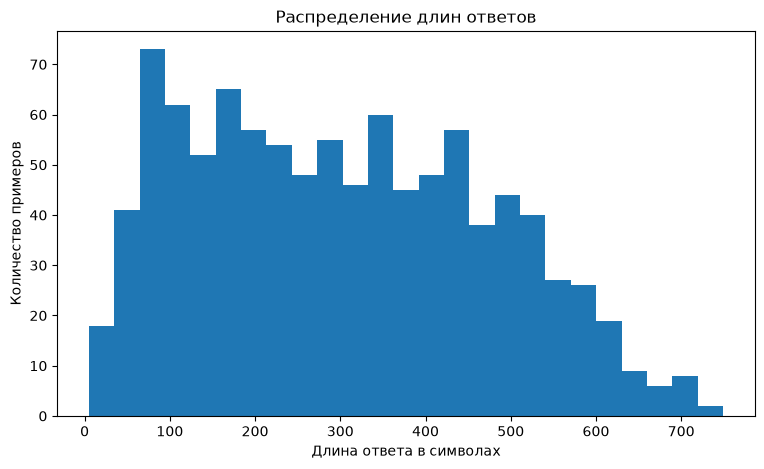

In [9]:
text_lengths = [len(text) for text in train_pairs["assistant"]]

plt.figure(figsize=(9, 5))
plt.hist(text_lengths, bins=25)
plt.xlabel("Длина ответа в символах")
plt.ylabel("Количество примеров")
plt.title("Распределение длин ответов")
plt.show()

На гистограмме видно, что ответы получились разной длины. Это ожидаемо, потому что в датасете есть и короткие ответы на вопросы, и более подробные объяснения. Длину пришлось ограничить, иначе моделям было бы сложнее обучаться на текстах

### Метрики и генерация

Для оценки качества использую `BLEU` и `METEOR`\
`BLEU` проверяет, насколько слова и их сочетания в ответе модели совпадают с правильным ответом\
`METEOR` тоже сравнивает тексты, но немного по-другому учитывает совпадения слов

Обе метрики не показывают полностью, насколько ответ полезный или правильный по смыслу. Поэтому вывожу и сами ответы.

In [10]:
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

bleu = evaluate.load("bleu")
meteor = evaluate.load("meteor")

[nltk_data] Error loading wordnet: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading omw-1.4: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

In [11]:
def calculate_metrics(predictions, references):
    bleu_score = bleu.compute(
        predictions=predictions,
        references=references,
        smooth=True,
    )["bleu"]

    meteor_score = meteor.compute(
        predictions=predictions,
        references=references,
    )["meteor"]

    return {"BLEU": bleu_score, "METEOR": meteor_score}

In [12]:
def generate_smol(model, question):
    prompt_ids = make_smol_prompt(question)
    input_ids = torch.tensor([prompt_ids], dtype=torch.long).to(device)
    attention_mask = torch.ones_like(input_ids)

    model.eval()
    with torch.inference_mode():
        output = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=MAX_TARGET_LENGTH,
            do_sample=False,
            repetition_penalty=1.1,
            no_repeat_ngram_size=3,
            pad_token_id=smol_tokenizer.pad_token_id,
            eos_token_id=smol_tokenizer.eos_token_id,
        )

    answer_ids = output[0][input_ids.shape[1]:]
    answer = smol_tokenizer.decode(answer_ids, skip_special_tokens=True)
    return answer.strip()


def generate_flan(model, question):
    prompt = make_flan_prompt(question)
    inputs = flan_tokenizer(prompt, return_tensors="pt").to(device)

    model.eval()
    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_LENGTH,
            do_sample=False,
            num_beams=1,
        )

    return flan_tokenizer.decode(output[0], skip_special_tokens=True).strip()

In [13]:
def evaluate_answers(model, generate_function, validation_data):
    predictions = []

    for example in tqdm(validation_data, desc="Генерация ответов"):
        answer = generate_function(model, example["user"])
        predictions.append(answer)

    return predictions


def clear_memory():
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [14]:
example_question = val_pairs[0]["user"]
example_answer = val_pairs[0]["assistant"]

print("Запрос пользователя:", example_question)
print("Правильный ответ:", example_answer)

Запрос пользователя: Given the text: On this website we recommend many images about Aline Skirt that we have collected from various sites from many image inspiration, and of course what we recommend is the most excellent of image for a line skirts uk . If you like the image on our website, please do not hesitate to visit again and get inspiration from all the houses in the image of our web image. And if you want to see more images, we recommend the gallery below. You can see the picture as a reference image from your Aline Skirt. Thank you for seeing gallery of Aline Skirt, we would be very happy if you come back. How would you describe the A-line skirt style?
Правильный ответ: The A-line skirt style is a type of skirt that flares out from the waist to create a triangular shape, resembling the letter "A". It is a popular and timeless piece of clothing that can be worn in a variety of occasions, from casual to formal.


Для примера взят вопрос из валидационной выборки про фасон юбки A-line. Правильный ответ объясняет, что юбка расширяется от талии книзу

### Обучение и валидация

После каждой эпохи считается `loss` на обучающей и валидационной выборках, а также `BLEU` и `METEOR`.\
Сохраняются веса с наименьшим `validation loss`. Если он три эпохи подряд не улучшается, останавливаю обучение 


In [15]:
def evaluate_loss(model, validation_loader):
    model.eval()
    total_loss = 0

    with torch.inference_mode():
        for batch in tqdm(validation_loader, desc="Validation loss", leave=False):
            batch = {name: value.to(device) for name, value in batch.items()}
            outputs = model(**batch)
            total_loss += outputs.loss.item()

    return total_loss / len(validation_loader)


def train_model(model, train_loader, validation_loader, validation_data,
                generate_function, optimizer, best_dir, num_epochs=NUM_EPOCHS):
    history = []
    best_loss = float("inf")
    best_epoch = 0
    bad_epochs = 0
    best_path = best_dir / "best_weights.pt"
    best_dir.mkdir(parents=True, exist_ok=True)

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        total_loss = 0

        for step, batch in enumerate(tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs}")):
            batch = {name: value.to(device) for name, value in batch.items()}

            outputs = model(**batch)
            loss = outputs.loss
            total_loss += loss.item()

            group_start = (step // GRADIENT_ACCUMULATION) * GRADIENT_ACCUMULATION
            group_size = min(GRADIENT_ACCUMULATION, len(train_loader) - group_start)
            (loss / group_size).backward()

            if (step + 1) % GRADIENT_ACCUMULATION == 0 or step + 1 == len(train_loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

        train_loss = total_loss / len(train_loader)
        val_loss = evaluate_loss(model, validation_loader)

        predictions = evaluate_answers(model, generate_function, validation_data)
        metrics = calculate_metrics(predictions, validation_data["assistant"])

        history.append({
            "Эпоха": epoch + 1,
            "Train loss": train_loss,
            "Val loss": val_loss,
            "BLEU": metrics["BLEU"],
            "METEOR": metrics["METEOR"],
        })

        print(f"Epoch {epoch + 1}: train loss = {train_loss:.4f}	val loss = {val_loss:.4f}")
        print(f"BLEU = {metrics['BLEU']:.4f}	METEOR = {metrics['METEOR']:.4f}")

        if val_loss < best_loss - MIN_DELTA:
            best_loss = val_loss
            best_epoch = epoch + 1
            bad_epochs = 0
            torch.save(model.state_dict(), best_path)
            print("Сохранена лучшая модель. Эпоха:", best_epoch)
        else:
            bad_epochs += 1

        if EARLY_STOPPING and bad_epochs >= PATIENCE:
            print("Ранняя остановка после эпохи:", epoch + 1)
            break

    weights = torch.load(best_path, map_location="cpu", weights_only=True)
    model.load_state_dict(weights)
    del weights
    clear_memory()

    print("Лучшая эпоха:", best_epoch)
    print("Лучший validation loss:", round(best_loss, 4))

    return pd.DataFrame(history)


## SmolLM2-135M-Instruct (decoder-only)

### Подготовка данных

Для SmolLM2 использую готовый шаблон чата \
В одной последовательности объединяем запрос и ответ, но ошибка обучения считается по токенам ответа

In [16]:
class SmolDataset(Dataset):
    def __init__(self, pairs, tokenizer):
        self.pairs = pairs
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        example = self.pairs[index]

        question = example["user"]
        answer = example["assistant"]

        prompt_ids = make_smol_prompt(question)

        answer_ids = self.tokenizer.encode(
            answer,
            add_special_tokens=False
        )

        answer_ids = answer_ids + [self.tokenizer.eos_token_id]

        input_ids = prompt_ids + answer_ids
        labels = [-100] * len(prompt_ids) + answer_ids

        return {
            "input_ids": torch.tensor(input_ids, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long),
            "attention_mask": torch.ones(len(input_ids), dtype=torch.long)
        }

In [17]:
smol_train_dataset = SmolDataset(train_pairs, smol_tokenizer)
smol_val_dataset = SmolDataset(val_pairs, smol_tokenizer)

smol_train_loader = DataLoader(
    smol_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

smol_val_loader = DataLoader(
    smol_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

sample = smol_train_dataset[0]
print("Input ids:", sample["input_ids"].shape)
print("Labels:", sample["labels"].shape)
print("Токенов ответа:", (sample["labels"] != -100).sum().item())

answer_mask = sample["labels"] != -100
assert answer_mask.sum().item() > 0
assert torch.equal(sample["input_ids"][answer_mask], sample["labels"][answer_mask])
assert sample["labels"][-1].item() == smol_tokenizer.eos_token_id
assert sample["labels"][answer_mask].tolist() == smol_tokenizer.encode(train_pairs[0]["assistant"], add_special_tokens=False) + [smol_tokenizer.eos_token_id]
print("Маскировка запроса работает")


Input ids: torch.Size([204])
Labels: torch.Size([204])
Токенов ответа: 97
Маскировка запроса работает


### Zero-shot

In [18]:
smol_model = AutoModelForCausalLM.from_pretrained(
    SMOL_MODEL_NAME,
    cache_dir=HF_CACHE_DIR,
    dtype=torch.float32,
).to(device)

smol_zero_answer = generate_smol(smol_model, example_question)
smol_simple_zero = generate_smol(smol_model, "Hello! How are you?")

print("Запрос:", example_question)
print("Ответ SmolLM2 до обучения:", smol_zero_answer)
print("Правильный ответ:", example_answer)
print("Простой запрос:", "Hello! How are you?")
print("Ответ SmolLM2:", smol_simple_zero)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Запрос: Given the text: On this website we recommend many images about Aline Skirt that we have collected from various sites from many image inspiration, and of course what we recommend is the most excellent of image for a line skirts uk . If you like the image on our website, please do not hesitate to visit again and get inspiration from all the houses in the image of our web image. And if you want to see more images, we recommend the gallery below. You can see the picture as a reference image from your Aline Skirt. Thank you for seeing gallery of Aline Skirt, we would be very happy if you come back. How would you describe the A-line skirt style?
Ответ SmolLM2 до обучения: The A-Line skirt style is characterized by its sleek silhouette, elegant curves, and subtle elegance. It's often associated with feminine elegance and sophistication. The A- Line skirt typically features long, flowing sleeves that drape elegantly around the body, creating a sense of fluidity and movement. The sleeve

До обучения SmolLM2 уже пишет связный ответ и нормально реагирует на простое приветствие. Но в ответе про юбку она добавляет рукава и детали, которые скорее относятся к другой одежде

In [19]:
smol_zero_predictions = evaluate_answers(
    smol_model,
    generate_smol,
    val_pairs,
)

smol_zero_metrics = calculate_metrics(
    smol_zero_predictions,
    val_pairs["assistant"],
)

smol_zero_metrics

Генерация ответов:   0%|          | 0/100 [00:00<?, ?it/s]

{'BLEU': 0.02932879836898505, 'METEOR': np.float64(0.24578903627625212)}

На всех 100 валидационных примерах исходная SmolLM2 получила `BLEU = 0.0293` и `METEOR = 0.2458`. BLEU пока довольно низкий, поэтому дальше проверим, поможет ли обучение

### Дообучение SmolLM2-135M-Instruct

In [20]:
smol_model.config.use_cache = False
smol_model.gradient_checkpointing_enable()

smol_optimizer = torch.optim.AdamW(
    smol_model.parameters(),
    lr=LEARNING_RATE,
)

smol_history = train_model(
    smol_model,
    smol_train_loader,
    smol_val_loader,
    val_pairs,
    generate_smol,
    smol_optimizer,
    SMOL_FINETUNED_DIR,
)

smol_history


Epoch 1/10:   0%|          | 0/1000 [00:00<?, ?it/s]

Validation loss:   0%|          | 0/100 [00:00<?, ?it/s]

Генерация ответов:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1: train loss = 1.5542	val loss = 1.6202
BLEU = 0.0514	METEOR = 0.2488
Сохранена лучшая модель. Эпоха: 1


Epoch 2/10:   0%|          | 0/1000 [00:00<?, ?it/s]

...

Epoch 4/10:   0%|          | 0/1000 [00:00<?, ?it/s]

Validation loss:   0%|          | 0/100 [00:00<?, ?it/s]

Генерация ответов:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 4: train loss = 0.4298	val loss = 1.9692
BLEU = 0.0524	METEOR = 0.2392
Ранняя остановка после эпохи: 4
Лучшая эпоха: 1
Лучший validation loss: 1.6202


,Эпоха,Train loss,Val loss,BLEU,METEOR
0,1,1.554198,1.620213,0.051401,0.248770
1,2,1.077219,1.647833,0.056466,0.243237
2,3,0.704483,1.803629,0.050600,0.248535
3,4,0.429818,1.969196,0.052441,0.239248


У SmolLM2 лучшей оказалась **первая эпоха**. Потом `train loss` продолжал уменьшаться, а `validation loss`, наоборот, рос. На четвёртой эпохе сработала ранняя остановка. Похоже на переобучение: модель всё лучше запоминает обучающие данные, но на новых примерах лучше не становится

In [21]:
smol_model.gradient_checkpointing_disable()
smol_model.config.use_cache = True

smol_model.save_pretrained(SMOL_FINETUNED_DIR)
smol_tokenizer.save_pretrained(SMOL_FINETUNED_DIR)

print("Лучшая модель сохранена в:", SMOL_FINETUNED_DIR.resolve())


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Лучшая модель сохранена в: D:\МАГА\2 курс\Разговорный ИИ\lr_2\models\smollm2_135m_best_val_full


### Проверка SmolLM2-135M-Instruct после обучения

In [22]:
smol_finetuned_answer = generate_smol(smol_model, example_question)
smol_simple_finetuned = generate_smol(smol_model, "Hello! How are you?")

print("Запрос:", example_question)
print("До обучения:", smol_zero_answer)
print("После обучения:", smol_finetuned_answer)
print("Правильный ответ:", example_answer)
print("Простой запрос:", "Hello! How are you?")
print("До обучения:", smol_simple_zero)
print("После обучения:", smol_simple_finetuned)

Запрос: Given the text: On this website we recommend many images about Aline Skirt that we have collected from various sites from many image inspiration, and of course what we recommend is the most excellent of image for a line skirts uk . If you like the image on our website, please do not hesitate to visit again and get inspiration from all the houses in the image of our web image. And if you want to see more images, we recommend the gallery below. You can see the picture as a reference image from your Aline Skirt. Thank you for seeing gallery of Aline Skirt, we would be very happy if you come back. How would you describe the A-line skirt style?
До обучения: The A-Line skirt style is characterized by its sleek silhouette, elegant curves, and subtle elegance. It's often associated with feminine elegance and sophistication. The A- Line skirt typically features long, flowing sleeves that drape elegantly around the body, creating a sense of fluidity and movement. The sleeves are usually 

После обучения ответ SmolLM2 на вопрос про юбку стал короче, но точного объяснения фасона всё равно нет\
А на обычное приветствие модель почему-то стала отвечать совсем не так, как раньше

In [23]:
smol_finetuned_predictions = evaluate_answers(
    smol_model,
    generate_smol,
    val_pairs,
)

smol_finetuned_metrics = calculate_metrics(
    smol_finetuned_predictions,
    val_pairs["assistant"],
)

smol_finetuned_metrics

Генерация ответов:   0%|          | 0/100 [00:00<?, ?it/s]

{'BLEU': 0.051401424068411694, 'METEOR': np.float64(0.24877032320597958)}

После обучения `BLEU` вырос до **0.0514**, а `METEOR` до **0.2488**\
Получается, по BLEU улучшение видно, но изменение METEOR совсем небольшое. Судя по конкретному примеру и метрикам, заметного улучшения качества ответов у модели нет

In [24]:
del smol_model
del smol_optimizer
clear_memory()

## FLAN-T5-small (encoder-decoder)

### Подготовка данных

У FLAN-T5 запрос поступает в энкодер, а декодер учится генерировать правильный ответ. В отличие от SmolLM2, здесь не нужно собирать запрос и ответ в одну последовательность.

In [25]:
class FlanDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        question = self.data[index]["user"]
        answer = self.data[index]["assistant"]

        inputs = self.tokenizer(
            make_flan_prompt(question),
            max_length=MAX_INPUT_LENGTH,
            truncation=True,
            return_tensors="pt",
        )

        targets = self.tokenizer(
            text_target=answer,
            max_length=MAX_TARGET_LENGTH,
            truncation=True,
            return_tensors="pt",
        )

        return {
            "input_ids": inputs["input_ids"][0],
            "attention_mask": inputs["attention_mask"][0],
            "labels": targets["input_ids"][0],
        }

In [26]:
flan_train_dataset = FlanDataset(train_pairs, flan_tokenizer)
flan_val_dataset = FlanDataset(val_pairs, flan_tokenizer)

flan_train_loader = DataLoader(
    flan_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

flan_val_loader = DataLoader(
    flan_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

sample = flan_train_dataset[0]
print("Input ids:", sample["input_ids"].shape)
print("Labels:", sample["labels"].shape)


Input ids: torch.Size([92])
Labels: torch.Size([102])


### Zero-shot

In [27]:
flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    FLAN_MODEL_NAME,
    cache_dir=HF_CACHE_DIR,
).to(device)

flan_zero_answer = generate_flan(flan_model, example_question)

print("Запрос:", example_question)
print("Ответ FLAN-T5 до обучения:", flan_zero_answer)
print("Правильный ответ:", example_answer)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Запрос: Given the text: On this website we recommend many images about Aline Skirt that we have collected from various sites from many image inspiration, and of course what we recommend is the most excellent of image for a line skirts uk . If you like the image on our website, please do not hesitate to visit again and get inspiration from all the houses in the image of our web image. And if you want to see more images, we recommend the gallery below. You can see the picture as a reference image from your Aline Skirt. Thank you for seeing gallery of Aline Skirt, we would be very happy if you come back. How would you describe the A-line skirt style?
Ответ FLAN-T5 до обучения: a line skirts uk
Правильный ответ: The A-line skirt style is a type of skirt that flares out from the waist to create a triangular shape, resembling the letter "A". It is a popular and timeless piece of clothing that can be worn in a variety of occasions, from casual to formal.


У исходной FLAN-T5 на вопрос про юбку получился ответ всего из нескольких слов: `a line skirts uk`. Это фрагмент исходного вопроса, а не объяснение фасона

In [28]:
flan_zero_predictions = evaluate_answers(
    flan_model,
    generate_flan,
    val_pairs,
)

flan_zero_metrics = calculate_metrics(
    flan_zero_predictions,
    val_pairs["assistant"],
)

flan_zero_metrics

Генерация ответов:   0%|          | 0/100 [00:00<?, ?it/s]

{'BLEU': 0.019295242533692927, 'METEOR': np.float64(0.0948407080016798)}

До обучения FLAN-T5 получила `BLEU = 0.0193` и `METEOR = 0.0948`. По обеим метрикам результат ниже, чем у исходной SmolLM2. Пока что FLAN-T5 хуже справляется именно с диалоговыми ответами

### Дообучение FLAN-T5-small

In [29]:
flan_optimizer = torch.optim.AdamW(
    flan_model.parameters(),
    lr=LEARNING_RATE,
)

flan_history = train_model(
    flan_model,
    flan_train_loader,
    flan_val_loader,
    val_pairs,
    generate_flan,
    flan_optimizer,
    FLAN_FINETUNED_DIR,
)

flan_history


Epoch 1/10:   0%|          | 0/1000 [00:00<?, ?it/s]

Validation loss:   0%|          | 0/100 [00:00<?, ?it/s]

Генерация ответов:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 1: train loss = 2.5242	val loss = 2.4181
BLEU = 0.0918	METEOR = 0.2125
Сохранена лучшая модель. Эпоха: 1


Epoch 2/10:   0%|          | 0/1000 [00:00<?, ?it/s]

...

Epoch 10/10:   0%|          | 0/1000 [00:00<?, ?it/s]

Validation loss:   0%|          | 0/100 [00:00<?, ?it/s]

Генерация ответов:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 10: train loss = 1.8937	val loss = 2.3055
BLEU = 0.1165	METEOR = 0.2591
Ранняя остановка после эпохи: 10
Лучшая эпоха: 7
Лучший validation loss: 2.3


,Эпоха,Train loss,Val loss,BLEU,METEOR
0,1,2.524227,2.418062,0.091767,0.212509
1,2,2.369370,2.371760,0.105501,0.229574
2,3,2.281880,2.340866,0.097432,0.218945
3,4,2.213076,2.319659,0.106225,0.223181
4,5,2.141976,2.305324,0.096057,0.214871
5,6,2.088103,2.303263,0.104394,0.235788
6,7,2.032957,2.299978,0.097663,0.236792
7,8,1.991058,2.301937,0.106322,0.243960
8,9,1.940936,2.306288,0.101963,0.248804
9,10,1.893662,2.305543,0.116503,0.259114


У FLAN-T5 `validation loss` снижался до **седьмой эпохи**, поэтому сохранились веса именно с неё\
Затем показатель немного вырос, а после десятой эпохи обучение остановилось\
Интересно, что BLEU и METEOR на последних эпохах ещё улучшались, но в я выбираю веса по `validation loss`

In [30]:
flan_model.save_pretrained(FLAN_FINETUNED_DIR)
flan_tokenizer.save_pretrained(FLAN_FINETUNED_DIR)

print("Лучшая модель сохранена в:", FLAN_FINETUNED_DIR.resolve())


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Лучшая модель сохранена в: D:\МАГА\2 курс\Разговорный ИИ\lr_2\models\flan_t5_small_best_val_full


### Проверка FLAN-T5-small после обучения

In [31]:
flan_finetuned_answer = generate_flan(flan_model, example_question)

print("Запрос:", example_question)
print("До обучения:", flan_zero_answer)
print("После обучения:", flan_finetuned_answer)
print("Правильный ответ:", example_answer)

Запрос: Given the text: On this website we recommend many images about Aline Skirt that we have collected from various sites from many image inspiration, and of course what we recommend is the most excellent of image for a line skirts uk . If you like the image on our website, please do not hesitate to visit again and get inspiration from all the houses in the image of our web image. And if you want to see more images, we recommend the gallery below. You can see the picture as a reference image from your Aline Skirt. Thank you for seeing gallery of Aline Skirt, we would be very happy if you come back. How would you describe the A-line skirt style?
До обучения: a line skirts uk
После обучения: The A-line skirt style is a skirt that is made of a thin, slender, and slender material. It is a great choice for a line skirts uk.
Правильный ответ: The A-line skirt style is a type of skirt that flares out from the waist to create a triangular shape, resembling the letter "A". It is a popular an

После обучения FLAN-T5 уже отвечает целым предложением, а не просто повторяет слова из запроса. Но в самом описании юбки ещё есть странные моменты. Значит, модель стала больше похожа на диалогового ассистента, но по одному примеру нельзя говорить, что модель научилась отвечать правильно

In [32]:
flan_finetuned_predictions = evaluate_answers(
    flan_model,
    generate_flan,
    val_pairs,
)

flan_finetuned_metrics = calculate_metrics(
    flan_finetuned_predictions,
    val_pairs["assistant"],
)

flan_finetuned_metrics

Генерация ответов:   0%|          | 0/100 [00:00<?, ?it/s]

{'BLEU': 0.09766313238166265, 'METEOR': np.float64(0.23679178786590804)}

Теперь у FLAN-T5 `BLEU = 0.0977` и `METEOR = 0.2368`. По сравнению с исходной моделью обе метрики выросли довольно сильно

In [33]:
del flan_model
del flan_optimizer
clear_memory()

## Сравнение метрик

Сравним `BLEU` и `METEOR` на одной валидационной выборке до и после обучения\
`loss` у разных архитектур напрямую сравнивать не очень правильно, поэтому для итогового сравнения использую метрики и примеры сгенерированных ответов.

In [ ]:
comparison = pd.DataFrame(
    [
        {"Модель": "SmolLM2 до обучения", **smol_zero_metrics},
        {"Модель": "SmolLM2 после обучения", **smol_finetuned_metrics},
        {"Модель": "FLAN-T5 до обучения", **flan_zero_metrics},
        {"Модель": "FLAN-T5 после обучения", **flan_finetuned_metrics},
    ]
).set_index("Модель")[["BLEU", "METEOR"]]

for name in ["SmolLM2", "FLAN-T5"]:
    result = comparison.loc[[f"{name} до обучения", f"{name} после обучения"]].T
    result.columns = ["До обучения", "После обучения"]

    result["Изменение"] = result["После обучения"] - result["До обучения"]
    result["Изменение"] = result["Изменение"].map(lambda x: f"{x:+.4f}")

    print(name)
    display(result.round(4))

SmolLM2


,До обучения,После обучения,Изменение
BLEU,0.0293,0.0514,+0.0221
METEOR,0.2458,0.2488,+0.0030


FLAN-T5


,До обучения,После обучения,Изменение
BLEU,0.0193,0.0977,+0.0784
METEOR,0.0948,0.2368,+0.1420


Из таблицы видно, что у SmolLM2 `BLEU` прибавил примерно **0.0221**, а `METEOR` только **0.0030**. У FLAN-T5 изменения больше: **0.0784** по BLEU и **0.1420** по METEOR. При этом после обучения FLAN-T5 лучше по BLEU, а у SmolLM2 чуть выше METEOR\
Поэтому нельзя сказать, что одна модель оказалась лучше абсолютно по всему.

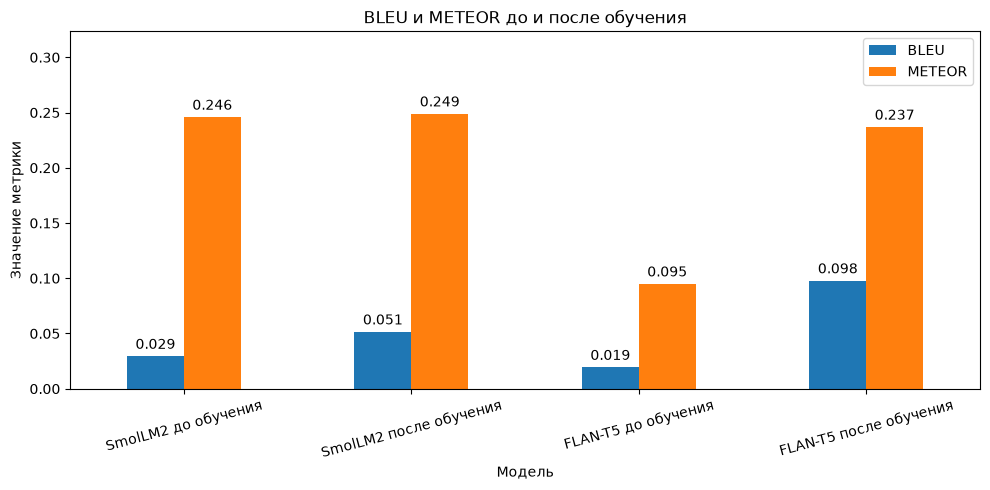

In [35]:
ax = comparison[["BLEU", "METEOR"]].plot(
    kind="bar",
    figsize=(10, 5),
    rot=15,
)

max_score = comparison[["BLEU", "METEOR"]].max().max()
plt.ylim(0, min(1, max(0.1, max_score * 1.3)))
plt.ylabel("Значение метрики")
plt.xlabel("Модель")
plt.title("BLEU и METEOR до и после обучения")
plt.legend(loc="upper right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

На столбчатом графике хорошо заметно, насколько сильнее изменились метрики у FLAN-T5\
Особенно это видно по METEOR. У SmolLM2 столбцы METEOR почти одинаковые, хотя BLEU после обучения всё же подрос

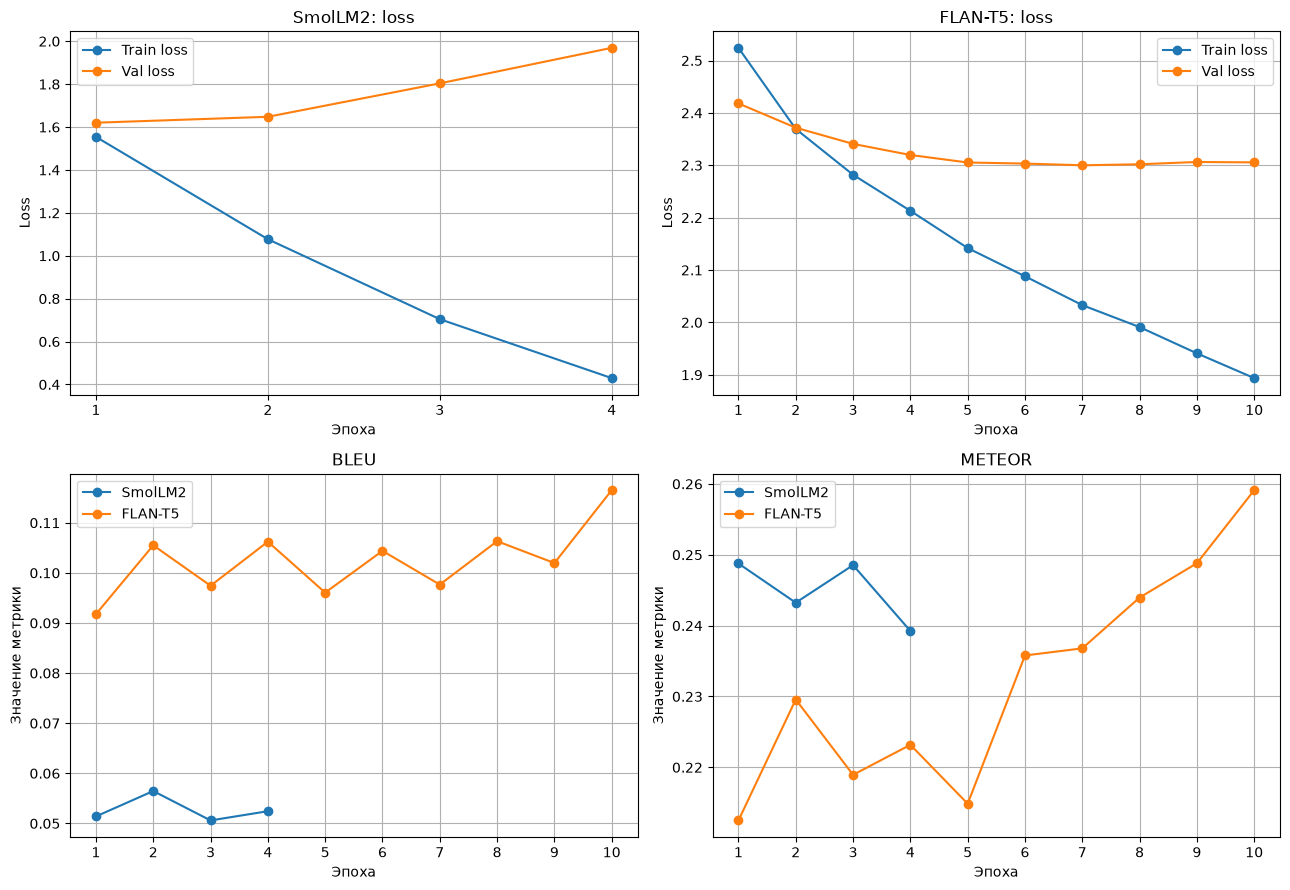

In [44]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for j, (history, name) in enumerate([(smol_history, "SmolLM2"), (flan_history, "FLAN-T5")]):
    axes[0, j].plot(history["Эпоха"], history["Train loss"], marker="o", label="Train loss")
    axes[0, j].plot(history["Эпоха"], history["Val loss"], marker="o", label="Val loss")
    axes[0, j].set_title(name + ": loss")
    axes[0, j].set_xlabel("Эпоха")
    axes[0, j].set_ylabel("Loss")
    axes[0, j].legend()
    axes[0, j].grid(True)

for j, metric in enumerate(["BLEU", "METEOR"]):
    axes[1, j].plot(smol_history["Эпоха"], smol_history[metric], marker="o", label="SmolLM2")
    axes[1, j].plot(flan_history["Эпоха"], flan_history[metric], marker="o", label="FLAN-T5")
    axes[1, j].set_title(metric)
    axes[1, j].set_xlabel("Эпоха")
    axes[1, j].set_ylabel("Значение метрики")
    axes[1, j].legend()
    axes[1, j].grid(True)

for ax in axes.flat:
    axes[0, 0].set_xticks(smol_history["Эпоха"])
    axes[0, 1].set_xticks(flan_history["Эпоха"])

    max_epoch = max(smol_history["Эпоха"].max(), flan_history["Эпоха"].max())

    axes[1, 0].set_xticks(range(1, int(max_epoch) + 1))
    axes[1, 1].set_xticks(range(1, int(max_epoch) + 1))

plt.tight_layout()
plt.show()


На графиках `loss` у SmolLM2 видно, что обучение и валидация довольно быстро пошли в разные стороны\
У FLAN-T5 снижение ошибки на валидации продолжалось дольше\
Сами BLEU и METEOR менялись неровно, поэтому ориентироваться только на результат одной эпохи не очень надёжно

### Лучшие эпохи

Здесь посмотрим, на какой эпохе у каждой модели был минимальный `validation loss`. Именно эти веса используются для финальной генерации ответов и подсчёта метрик

In [37]:
best_results = pd.DataFrame([
    {"Модель": "SmolLM2", **smol_history.loc[smol_history["Val loss"].idxmin()].to_dict()},
    {"Модель": "FLAN-T5", **flan_history.loc[flan_history["Val loss"].idxmin()].to_dict()},
])

best_results

,Модель,Эпоха,Train loss,Val loss,BLEU,METEOR
0,SmolLM2,1.0,1.554198,1.620213,0.051401,0.248770
1,FLAN-T5,7.0,2.032957,2.299978,0.097663,0.236792


Лучшая эпоха у SmolLM2 оказалась **1**, а у FLAN-T5 **7**. Это ещё раз показывает, что больше эпох не всегда значит лучше. При этом у FLAN-T5 на десятой эпохе метрики были выше, но её `validation loss` уже не был минимальным, поэтому для финального сравнения используются веса с седьмой эпохи

In [38]:
examples = pd.DataFrame(
    {
        "Запрос": val_pairs["user"][:5],
        "Правильный ответ": val_pairs["assistant"][:5],
        "SmolLM2 до": smol_zero_predictions[:5],
        "SmolLM2 после": smol_finetuned_predictions[:5],
        "FLAN-T5 до": flan_zero_predictions[:5],
        "FLAN-T5 после": flan_finetuned_predictions[:5],
    }
)

examples

,Запрос,Правильный ответ,SmolLM2 до,SmolLM2 после,FLAN-T5 до,FLAN-T5 после
0,"Given the text: On this website we recommend many images about Aline Skirt that we have collected from various sites from many image inspiration, ...","The A-line skirt style is a type of skirt that flares out from the waist to create a triangular shape, resembling the letter ""A"". It is a popular ...","The A-Line skirt style is characterized by its sleek silhouette, elegant curves, and subtle elegance. It's often associated with feminine elegance...",The A-Line skirt style is characterized by its long length and high neckline. It features a flowing and loose silhouette with a relaxed and effort...,a line skirts uk,"The A-line skirt style is a skirt that is made of a thin, slender, and slender material. It is a great choice for a line skirts uk."
1,"- If all else fails, consider calling a professional plumber to help clear the drain.",They have specialized tools and expertise to handle tough clogs and can ensure that the drain is fully cleared and functioning properly. It may co...,"I'm sorry for any inconvenience this may cause, but as an AI designed to assist with plumbing issues, I don't have the ability to provide immediat...","If you're feeling stuck and unable to find an answer on your own, don't hesitate to reach out to a professional plumber for assistance. A professi...","- If all else fails, consider calling a professional plumber to help clear the drain.","I do not have access to the information provided on this website. However, if you have any questions or concerns, please contact me directly."
2,What kind of material is used in the construction of any protective on-board equipment of the International Space Station?,"The protective on-board equipment of the International Space Station is made up of a variety of materials, including:\n\n1. Polycarbonate and acry...",The materials used for the construction and maintenance of the ISS's on-site equipment include:\n\n1. **Metal**: The ISS has two main sections: th...,The material used for the construction and maintenance of any on-site equipment of an international space station such as the ISS is typically alu...,material,"The material used in the construction of any protective on-board equipment of the International Space Station is steel, steel, and aluminum."
3,Identify the sample size used in the recent study analyzing the impact of digital technology on reading habits and differentiate the reading habit...,I do not have access to the specific study that you are referring to. Can you please provide more details or the source of the study?,"To identify the sample sizes for both digital and traditional readership, we can use the following methods:\n\n1. **Sampling method**: We can use ...","The current study analyzed the impact on reading habit using various methods such as surveys, interviews, and observational studies. The results s...",data on how digital technology has influenced reading habits in recent years.,The recent study analyzed the impact of digital technology on reading habits and differentiated reading habits between those who consume literatur...
4,Read the passage below and answer the question or follow the instruction: Can you transfer the style of the text material to a more formal tone?\n...,"Yes, the style of the text material can be transferred to a more formal tone. Here's an example:\n\nDear Aspire Technologies,\n\nWe would like to ...","Sure, I can help with that. Here's the revised passage in a more suitable style for a formal context:\n\nDear Aspire Tech Inc.,\n\nWe kindly reque...","Yes, it can be done. However, please ensure that the spelling error is corrected as per the instructions provided in the given passage.","Hey, Aspire Technologies, we don't mean to alarm you or anything, but you seem to have missedpelled the last half of your product's name. Next tim...","The passage mainly tells us that the style of the text material is not necessarily formal. How

Посмотрим ещё на несколько ответов из валидационной выборки. Здесь хорошо видно, что метрики полезны для сравнения в целом, но отдельные ответы всё равно нужно читать. Модель может написать похожие слова и при этом ошибиться в самой информации

In [ ]:
comparison.reset_index().to_csv(DATA_DIR / f"metrics_lab2_{MODE_NAME}_val.csv", index=False)
examples.to_csv(DATA_DIR / f"examples_lab2_{MODE_NAME}_val.csv", index=False)
smol_history.to_csv(DATA_DIR / f"smol_history_{MODE_NAME}.csv", index=False)
flan_history.to_csv(DATA_DIR / f"flan_history_{MODE_NAME}.csv", index=False)

print("Результаты сохранены в папке:", DATA_DIR.resolve())

Результаты сохранены в папке: D:\МАГА\2 курс\Разговорный ИИ\lr_2\data


: 

### Вывод

В этой работе я дообучил две небольшие диалоговые модели с разной архитектурой на одних и тех же примерах из `UltraChat 200k`. 
После обучения у обеих моделей вырос `BLEU`. 
У `SmolLM2` он изменился с **0.0293** до **0.0514**, а `METEOR` почти не изменился: **0.2458** и **0.2488**. 
При этом после первой эпохи у неё начал расти `validation loss`, хотя ошибка на обучающих данных уменьшалась.
Похоже, модель довольно быстро начала переобучаться

У `FLAN-T5` улучшение получилось заметнее: `BLEU` вырос с **0.0193** до **0.0977**, а `METEOR` с **0.0948** до **0.2368**. 
До обучения она часто отвечала просто коротким фрагментом текста, а после начала выдавать более похожие на обычные ответы предложения. 
Правда, в примере с юбкой ответ всё ещё не совсем правильный по смыслу

Получается, что в моём эксперименте дообучение оказалось полезным для обеих моделей, особенно для `FLAN-T5`. 
Но по отдельным примерам видно, что хорошие метрики ещё не гарантируют правильный ответ. 
И поскольку данных было немного, эти результаты относятся именно к выбранной выборке и настройкам обучения.